# Regularización: dropout en la RNN bidireccional

¿Agregar dropout a la RNN bidireccional mejora el F1 o reduce el sobreajuste?

El dropout apaga al azar (con probabilidad `p`) cada valor de `[h→_t ; h←_t]`, la salida de la RNN,
antes de las cabezas lineales. Solo actúa durante el entrenamiento (`model.train()`); al evaluar
(`model.eval()`) no apaga nada. Obliga a la red a no depender de unas pocas neuronas.

`nn.RNN(dropout=p)` no sirve acá: PyTorch solo lo aplica entre capas apiladas, y la red tiene una sola.
Por eso es una capa `nn.Dropout` aparte (ver `src/problem/*/bidirectional_rnn.py`).

Se entrena solo `bidirectional_rnn` (capitalización y puntuación) una vez por valor, con los mismos
datos, splits, semilla y épocas que el pipeline. Lo único que cambia es `p`.

**En Colab**: Entorno de ejecución → Cambiar tipo de entorno de ejecución → **GPU**, y que la rama
`feat/regularizacion` esté pusheada.

## 1. Setup

In [3]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
BRANCH = "feat/regularizacion"  # rama con notebooks/hyperparameters/regularization/regularization.py
REPO = "/content/TP2-Aprendizaje-Automatico-UBA"

if IN_COLAB:
    # Los resultados van a Drive: la máquina de Colab se borra al cerrar la sesión
    from google.colab import drive
    drive.mount("/content/drive")
    if not Path(REPO).exists():
        !git clone https://github.com/SebasAndres/TP2-Aprendizaje-Automatico-UBA.git {REPO}
    %cd {REPO}
    !git fetch origin && git checkout {BRANCH} && git pull
    !pip install -q uv && uv sync
    !mkdir -p /content/drive/MyDrive/tp2-models
    !if [ ! -L models ]; then rm -rf models && ln -s /content/drive/MyDrive/tp2-models models; fi
else:
    # Local: el notebook corre desde notebooks/hyperparameters/regularization/, subimos hasta la raíz del repo
    while not Path("pyproject.toml").exists():
        os.chdir("..")
print("Directorio:", Path.cwd())

Directorio: /content/TP2-Aprendizaje-Automatico-UBA


## 2. Barrido

In [4]:
PARAM = "dropout"
VALUES = [0.0, 0.1, 0.2, 0.3, 0.5]  # 0 = la red sin dropout (la de siempre)
# Weight decay fijo: 0 = AdamW sin decay, que es igual a Adam. Así solo cambia el dropout
WEIGHT_DECAY = 0.0

# Con pocas épocas no llega a sobreajustar y no se ve el efecto de la regularización
EPOCHS = 15
# Instancias por fuente (default del pipeline: 1000). Más datos = más lento
CAPITALIZATION_SIZE = 1000
PUNCTUATION_SIZE = 1000

In [5]:
VALUES_ARG = " ".join(str(v) for v in VALUES)
!MPLBACKEND=Agg uv run python -m notebooks.hyperparameters.regularization.regularization --param dropout --values {VALUES_ARG} --weight-decay {WEIGHT_DECAY} \
    --epochs {EPOCHS} --capitalization-size {CAPITALIZATION_SIZE} --punctuation-size {PUNCTUATION_SIZE}

2026-11-16 20:25:52,409 INFO src.data.preprocess: Fuente tatoeba: 1000 instancias
2026-11-16 20:25:52,421 INFO src.data.preprocess: Fuente rioplatense: 1000 instancias
2026-11-16 20:25:52,429 INFO src.data.preprocess: Fuente ted: 1000 instancias
2026-11-16 20:25:52,435 INFO src.data.preprocess: Fuente mrbeast: 1000 instancias
2026-11-16 20:25:52,439 INFO src.data.preprocess: Fuente peliculas: 1000 instancias
2026-11-16 20:25:52,448 INFO src.data.preprocess: Fuente simuladores: 1000 instancias
2026-11-16 20:25:52,454 INFO src.data.preprocess: Fuente okupas: 1000 instancias
2026-11-16 20:25:52,938 WARNING huggingface_hub.utils._http: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.



2026-11-16 20:25:55,210 INFO src.data.preprocess: Fuente tatoeba: 1000 instancias
2026-11-16 20:25:55,222 INFO src.data.preprocess: Fuente rioplatense: 1000 instancias
2026-11-16 20:25:55,230 INFO src.data.preprocess: F

## 3. Resultados

In [6]:
import matplotlib.pyplot as plt
from IPython.display import display

from notebooks.hyperparameters.regularization.regularization_plots import (
    best_value,
    latest_results,
    load_results,
    plot_control_f1,
    plot_gap,
    plot_loss_curves,
    summary_table,
)

%matplotlib inline

# Barrido a analizar: por defecto el último de este hiperparámetro.
# Para otro: RESULTS = Path("models/regularization/<día>__<hora>__dropout/results.json")
RESULTS = latest_results(PARAM)
report = load_results(RESULTS)
print("Resultados:", RESULTS)
print("Configuración:", report["config"])


def show_and_save(fig, name: str) -> None:
    """Muestra el gráfico y lo guarda como PNG junto al results.json (para adjuntar al PR)"""
    fig.savefig(RESULTS.parent / f"{name}.png", dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

Resultados: models/regularization/2026-11-16__20-26-02__dropout/results.json
Configuración: {'param': 'dropout', 'values': [0.0, 0.1, 0.2, 0.3, 0.5], 'dropout': 0.0, 'weight_decay': 0.0, 'epochs': 15, 'capitalization_size': 1000, 'punctuation_size': 1000, 'window': {'min_size': 5, 'max_size': 60, 'distribution': 'uniform'}, 'learning_rate': 0.001, 'grad_clip_norm': 1.0}


### Tabla

Por problema y valor de `dropout`:

- **época**: la época con mejor F1 en test (la que se queda el entrenamiento).
- **brecha**: F1 promedio de train menos el de test en esa época. Cuanto más grande, más sobreajusta.
- **test / control**: F1 macro promedio de las tareas del problema. **Comparar con control**: test ya se
  usó para elegir la época, así que su F1 es optimista.

In [7]:
print(summary_table(report))


CapitalizationProblem
         valor           época          brecha            test         control  ctrl capitalizacion
             0              12           0.150           0.538           0.461           0.461
           0.1              12           0.156           0.532           0.466           0.466
           0.2              12           0.154           0.529           0.453           0.453
           0.3               9           0.061           0.528           0.464           0.464
           0.5              12           0.136           0.534           0.460           0.460

PunctuationProblem
         valor           época          brecha            test         control  ctrl punt_inicial  ctrl punt_final
             0              13           0.025           0.638           0.647           0.755           0.538
           0.1              15           0.027           0.642           0.649           0.758           0.541
           0.2              15           0.02

### F1 en control

¿Con qué `p` generaliza mejor? Con `p` muy alto la red pierde información y el F1 cae.

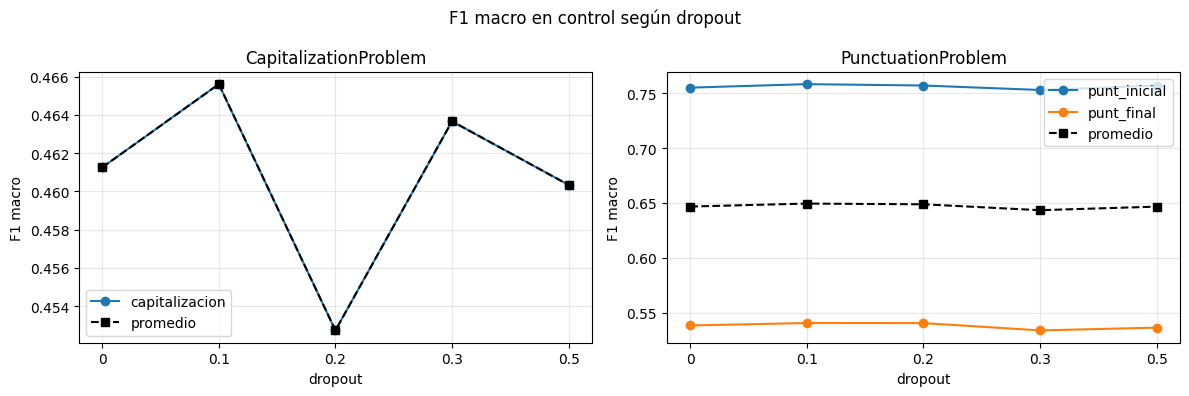

In [8]:
show_and_save(plot_control_f1(report, PARAM), "f1_control_dropout")

### Curvas de loss

Sin regularización, la loss de train (punteada) sigue bajando mientras la de test (llena) se estanca o
sube: la red memoriza train. Con regularización, la loss de train baja más lento y la de test debería
subir menos al final.

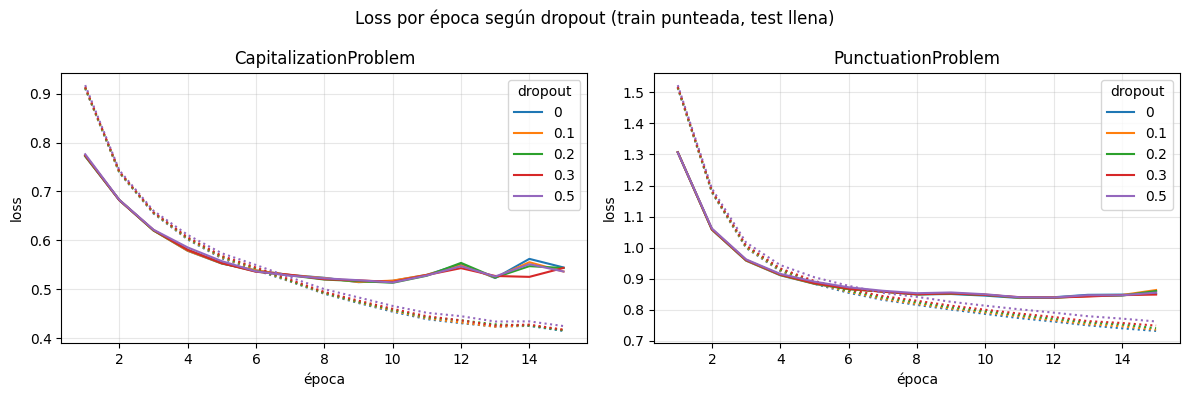

In [9]:
show_and_save(plot_loss_curves(report, PARAM), "loss_dropout")

### Sobreajuste

Brecha de F1 entre train y test en la mejor época. Si la regularización funciona, baja al aumentar el
valor; si baja pero el F1 de control también cae, el valor es demasiado grande (la red queda sub-ajustada).

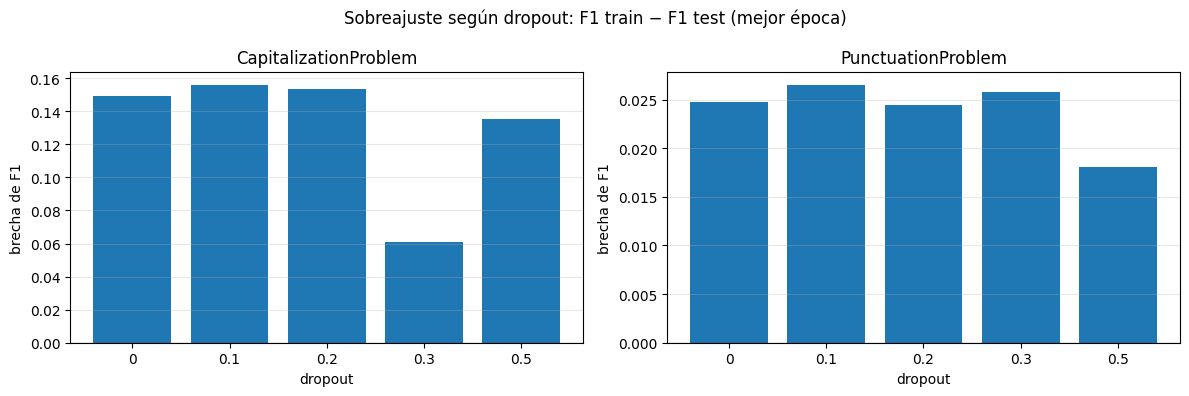

In [10]:
show_and_save(plot_gap(report, PARAM), "brecha_dropout")

## 4. Mejor valor por problema

In [11]:
for problem in report["problems"]:
    print(f"{problem}: {PARAM} = {best_value(report, problem):g}")

CapitalizationProblem: dropout = 0
PunctuationProblem: dropout = 0.1


## 5. Conclusión

**El dropout no mejora la RNN bidireccional más allá del ruido: queda en 0 en los dos problemas.**

El valor se elige con **test** (como la mejor época de cada red) y **control** confirma.

- **Capitalización → 0.** Ningún valor le gana en test (0.538; el resto entre 0.528 y 0.534). En control los
  valores saltan sin seguir el orden del dropout (0.461, 0.466, 0.453, 0.464, 0.460): es ruido. La brecha de
  0.3 (0.061) no es que generalice mejor: su mejor época es la 9 en lugar de la 12, cuando train todavía no
  había subido, y su F1 en test es el más bajo.
- **Puntuación → 0.** 0.1 y 0.2 ganan por +0.004 en test y +0.002 en control: menos que lo que dio el weight
  decay (λ = 1: +0.006 / +0.005), que ya estaba en el límite. Además se probó con weight decay 0 y puntuación
  usa λ = 1: la combinación de dos regularizaciones que por separado casi no aportan no está medida.

**Por qué casi no ayuda.** Con `lr = 1e-3` la red todavía está aprendiendo: en los dos problemas la mejor época
es la 12–15 de 15 (ver `../learning_rate.ipynb`, en la rama `feat/learning-rate`). La regularización sirve
cuando la red ya aprendió y empieza a memorizar train; acá el cuello de botella es el learning rate. Con `lr`
más alto, capitalización sobreajusta más (brecha ~0.2): después de fijar el `lr` del entrenamiento final
conviene repetir este barrido con esa configuración.

Es una sola semilla.
